# 03 · dv/v, noise floor, tides, run offsets
30-min stacks (moving 10 min), stretching vs all-January reference, inverse-variance averaged over offsets and lag sides, then over each repeater span (`s09`–`s10`).

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, numpy as np
from IPython.display import Image, display
from msdvv import load_config
cfg = load_config(); OUT = cfg['output_dir']; FIG = OUT + '/figs/'
pd.set_option('display.width', 200)

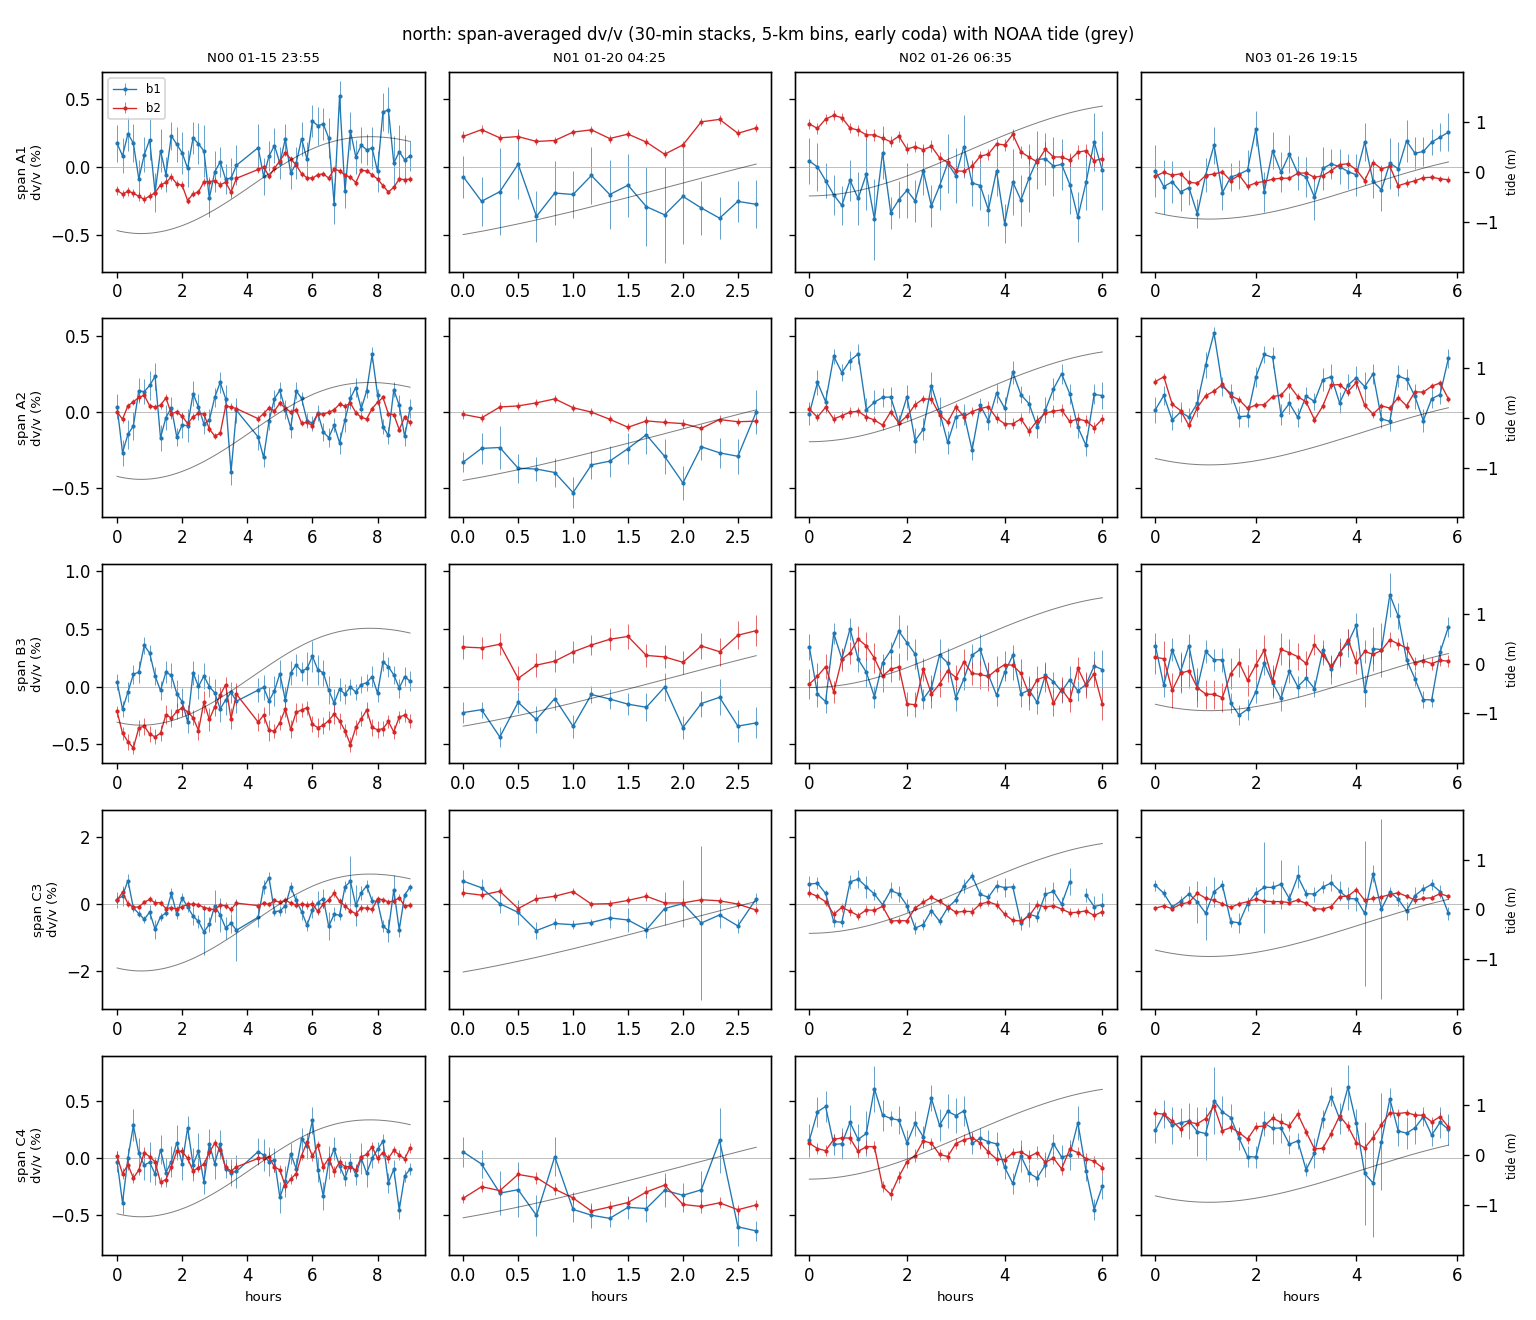

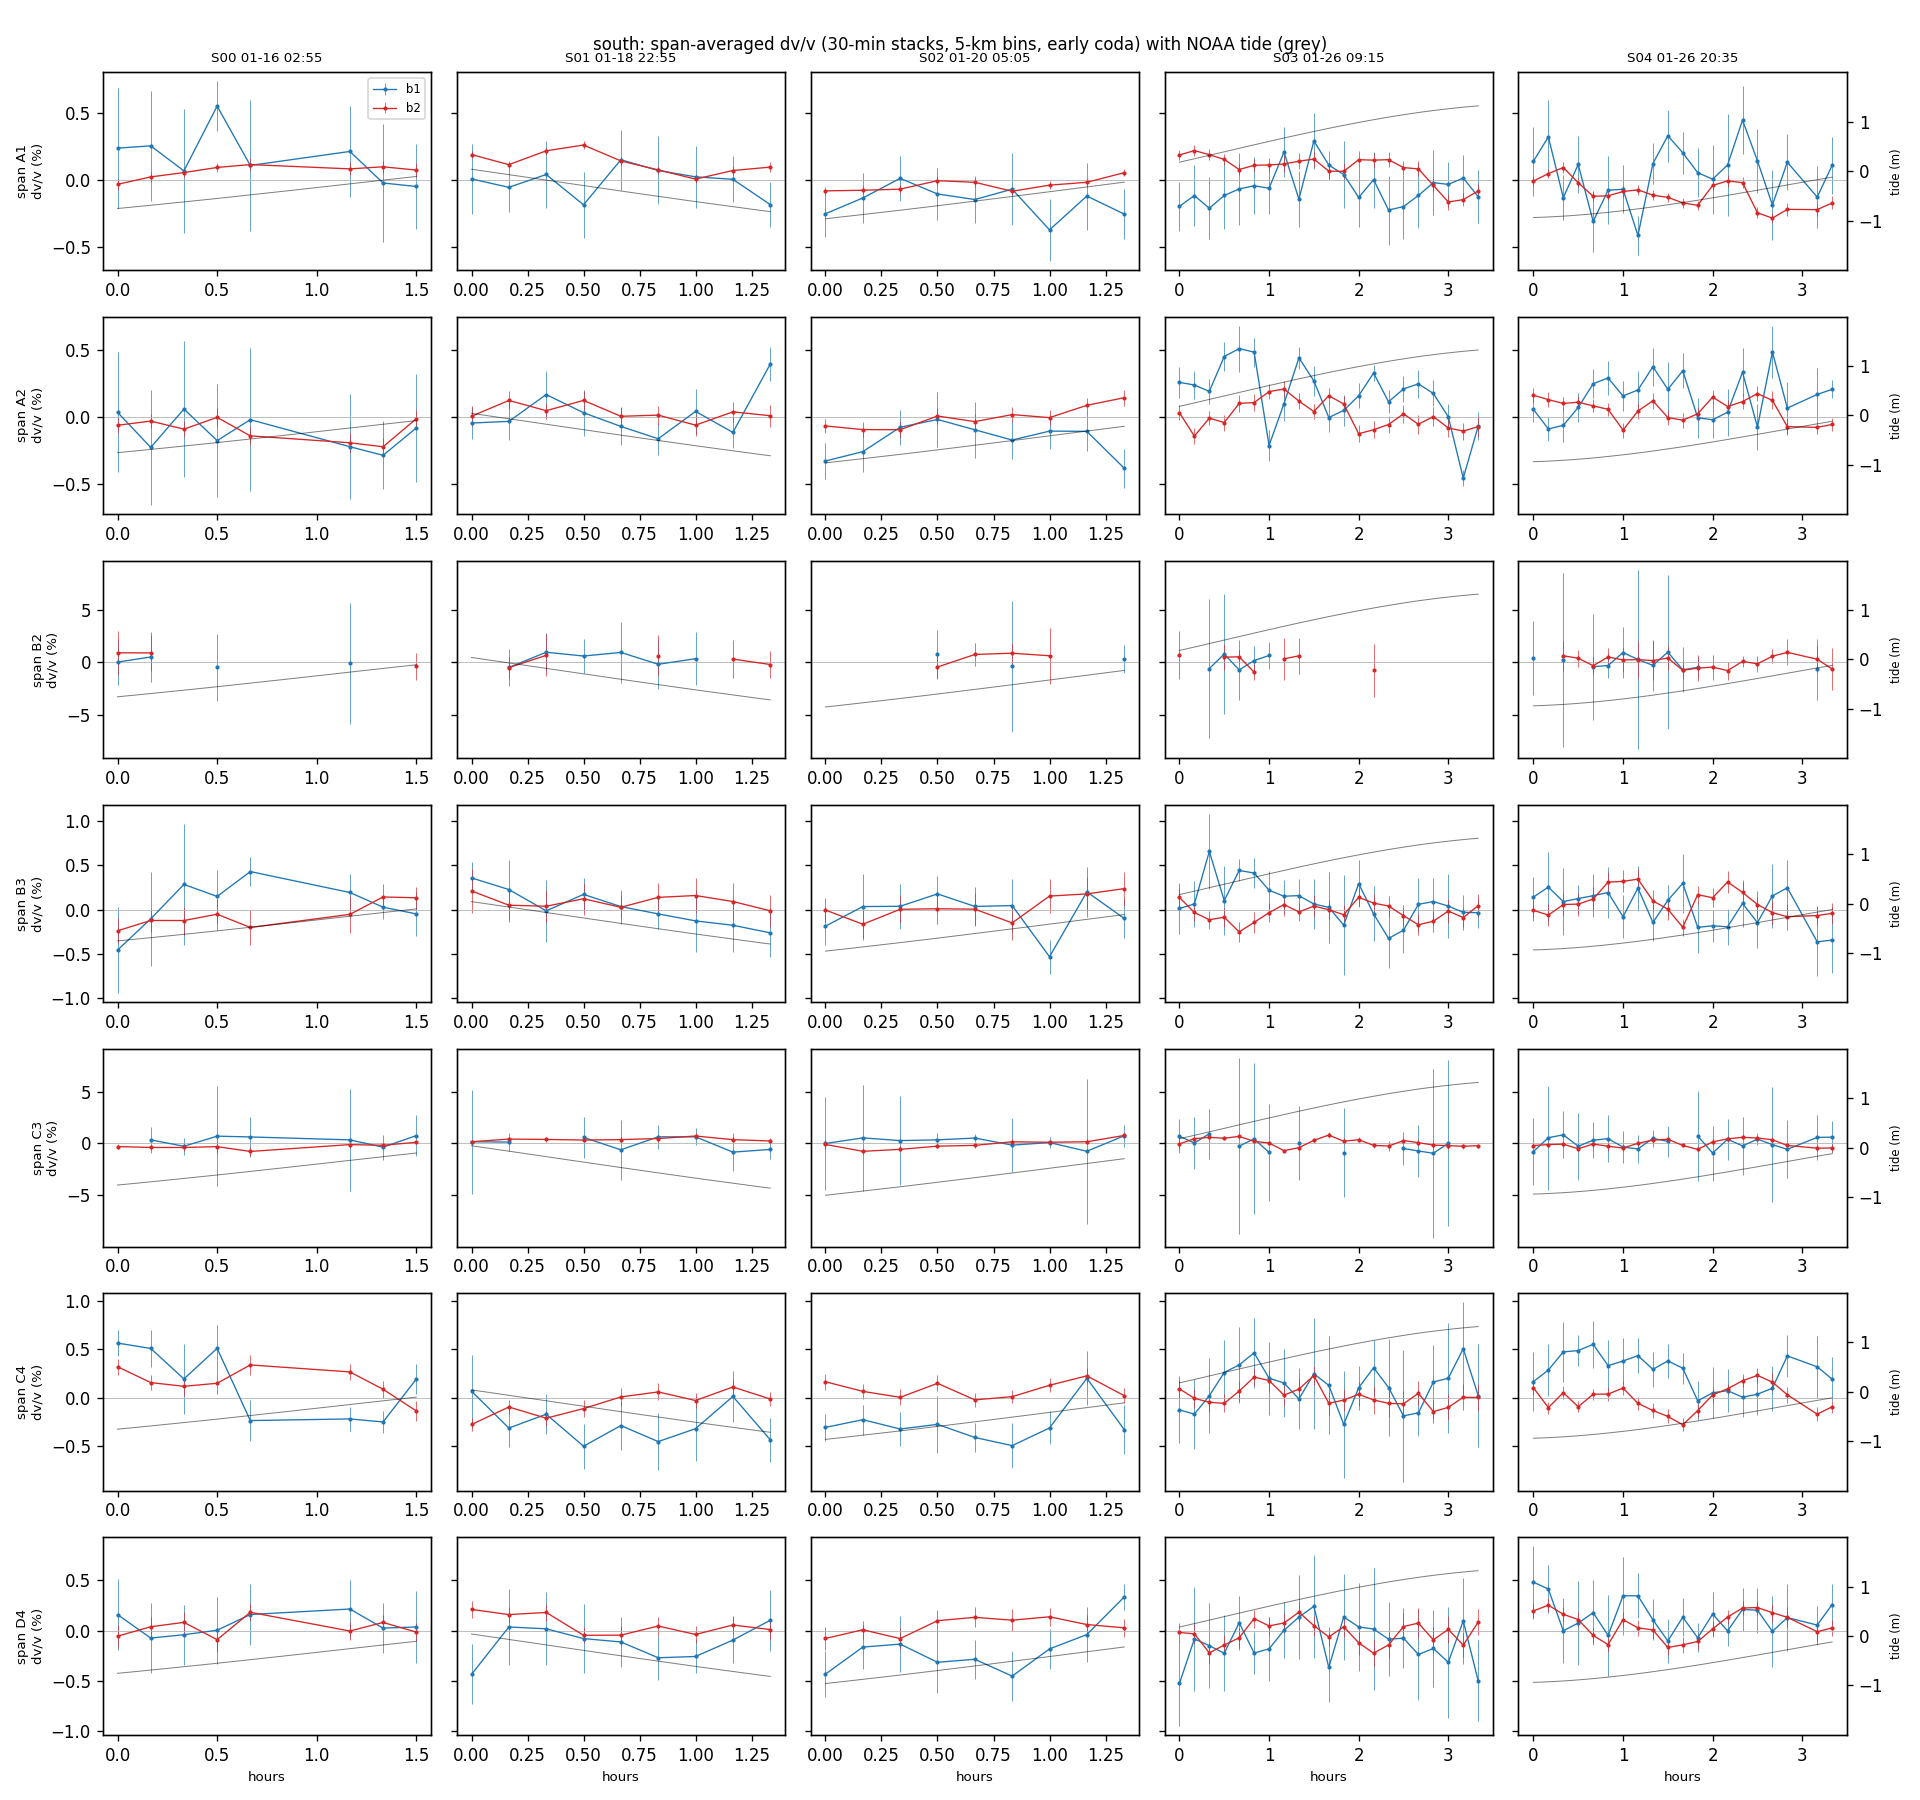

In [2]:
for c in ('north','south'): display(Image(f'{FIG}dvv_timeseries_{c}.png'))

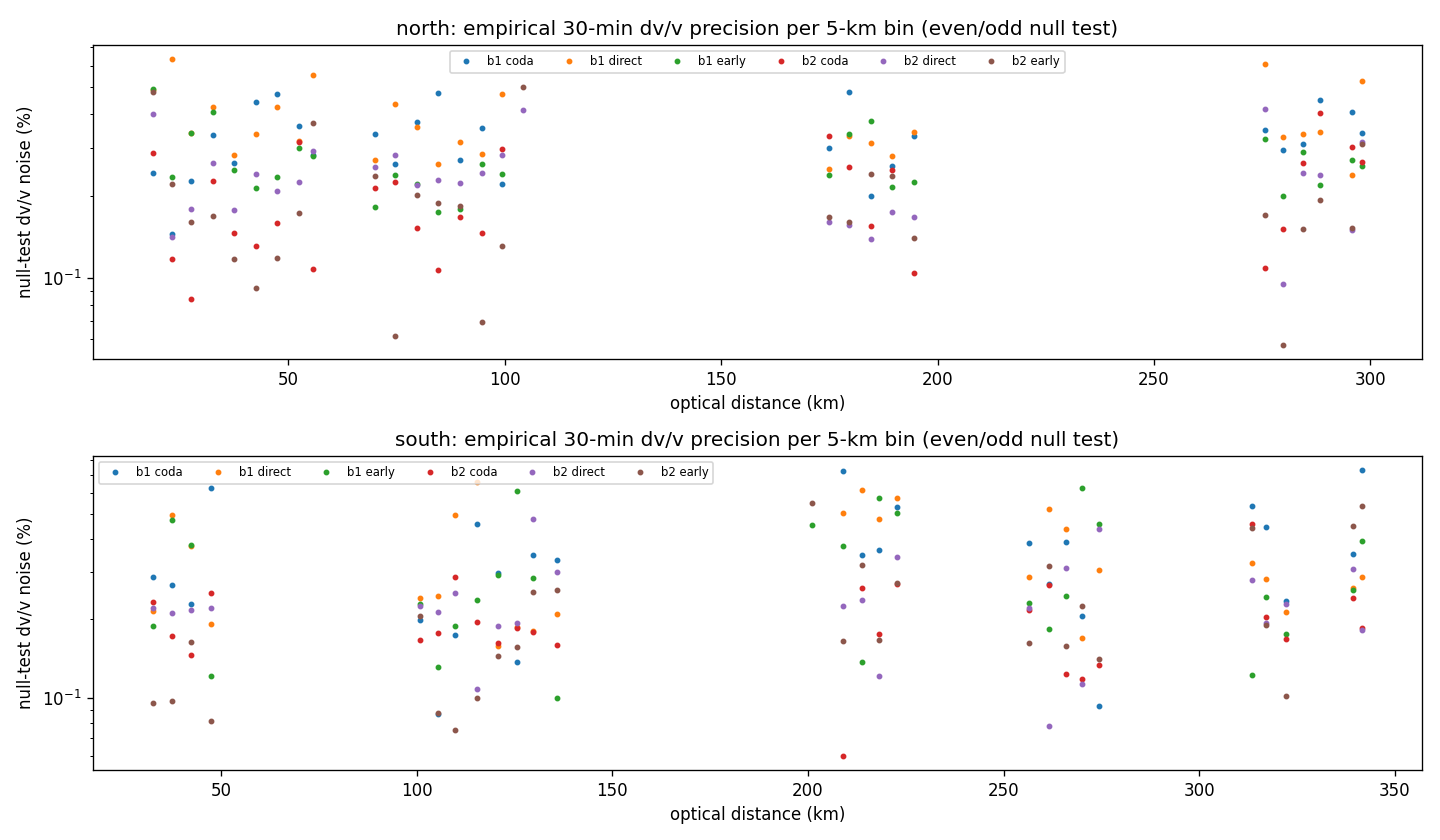

band              b1                      b2                
window          coda  direct   early    coda  direct   early
cable seg_id                                                
north A1      0.0009  0.0018  0.0014  0.0005  0.0006  0.0004
      A2      0.0019  0.0021  0.0017  0.0008  0.0012  0.0007
      B3      0.0022  0.0017  0.0015  0.0011  0.0008  0.0007
      C3      0.0035  0.0061  0.0032  0.0011  0.0042  0.0017
      C4      0.0022  0.0020  0.0017  0.0018  0.0012  0.0008
south A1      0.0012  0.0017  0.0015  0.0019  0.0011  0.0002
      A2      0.0005  0.0009  0.0010  0.0004  0.0005  0.0006
      B2      0.0000  0.0000  0.0045     NaN  0.0000  0.0055
      B3      0.0021  0.0023  0.0010  0.0006  0.0020  0.0005
      C3      0.0039  0.0029  0.0023  0.0022  0.0022  0.0016
      C4      0.0026  0.0021  0.0016  0.0014  0.0012  0.0010
      D4      0.0009  0.0023  0.0019  0.0013  0.0009  0.0015

In [3]:
display(Image(FIG + 'dvv_precision_map.png'))
fl = pd.read_csv(OUT + '/dvv/noise_floor.csv')
fl[fl.level=='5km'].pivot_table(index=['cable','seg_id'], columns=['band','window'], values='floor_span').round(4)

In [4]:
t = pd.read_csv(OUT + '/dvv/tide_regression.csv')
print('tests:', len(t), ' |z|>2:', (t.z.abs()>2).sum(), ' (≈', round(0.0455*len(t),1), 'expected by chance)')
t[(t.level=='5km') & (t.window=='early')][['cable','band','seg_id','beta_per_m','se_per_m','z']].round(5)

tests: 142  |z|>2: 9  (≈ 6.5 expected by chance)


,cable,band,seg_id,beta_per_m,se_per_m,z
25,north,b1,A1,0.00049,0.00034,1.42816
26,north,b1,A2,-0.00002,0.00034,-0.06192
27,north,b1,B3,0.00001,0.00041,0.01453
28,north,b1,C3,0.00051,0.00098,0.52391
29,north,b1,C4,-0.00097,0.00044,-2.21753
55,north,b2,A1,0.00005,0.00018,0.29104
56,north,b2,A2,-0.00014,0.00014,-0.98068
57,north,b2,B3,-0.00001,0.00029,-0.05110
58,north,b2,C3,-0.00007,0.00037,-0.19735
59,north,b2,C4,0.00000,0.00023,0.01844


In [5]:
r = pd.read_csv(OUT + '/dvv/run_means.csv')
r[(r.level=='5km') & (r.window=='early')].pivot_table(index=['cable','seg_id','band'], columns='run', values='dv').round(4)

run                   N00     N01     N02     N03     S00     S01     S02     S03     S04
cable seg_id band                                                                        
north A1     b1    0.0010 -0.0022 -0.0011 -0.0001     NaN     NaN     NaN     NaN     NaN
             b2   -0.0010  0.0023  0.0015 -0.0006     NaN     NaN     NaN     NaN     NaN
      A2     b1   -0.0001 -0.0030  0.0006  0.0013     NaN     NaN     NaN     NaN     NaN
             b2   -0.0001 -0.0003 -0.0003  0.0009     NaN     NaN     NaN     NaN     NaN
      B3     b1    0.0003 -0.0020  0.0013  0.0017     NaN     NaN     NaN     NaN     NaN
             b2   -0.0029  0.0032  0.0009  0.0020     NaN     NaN     NaN     NaN     NaN
      C3     b1   -0.0011 -0.0028  0.0014  0.0023     NaN     NaN     NaN     NaN     NaN
             b2   -0.0001  0.0012 -0.0016  0.0011     NaN     NaN     NaN     NaN     NaN
      C4     b1   -0.0004 -0.0032  0.0016  0.0024     NaN     NaN     NaN     NaN     NaN
             b2   -0.0003 -0.0034  0.0003  0.0029     NaN     NaN     NaN     NaN     NaN
south A1     b1       NaN     NaN     NaN     NaN  0.0017 -0.0002 -0.0016 -0.0006  0.0004
             b2       NaN     NaN     NaN     NaN  0.0006  0.0013 -0.0004  0.0008 -0.0011
      A2     b1       NaN     NaN     NaN     NaN -0.0011  0.0002 -0.0017  0.0017  0.0015
             b2       NaN     NaN     NaN     NaN -0.0009  0.0003 -0.0000  0.0001  0.0006
      B2     b1       NaN     NaN     NaN     NaN -0.0001  0.0037  0.0024  0.0006 -0.0000
             b2       NaN     NaN     NaN     NaN  0.0049  0.0018  0.0046  0.0015  0.0005
      B3     b1       NaN     NaN     NaN     NaN  0.0006  0.0002 -0.0003  0.0009  0.0002
             b2       NaN     NaN     NaN     NaN -0.0006  0.0009  0.0003 -0.0003  0.0009
      C3     b1       NaN     NaN     NaN     NaN  0.0031  0.0002  0.0018 -0.0017  0.0010
             b2       NaN     NaN     NaN     NaN -0.0029  0.0039 -0.0007  0.0010 -0.0003
      C4     b1       NaN     NaN     NaN     NaN  0.0016 -0.0027 -0.0027  0.0011  0.0026
             b2       NaN     NaN     NaN     NaN  0.0016 -0.0006  0.0008  0.0002 -0.0001
      D4     b1       NaN     NaN     NaN     NaN  0.0006 -0.0012 -0.0019 -0.0011  0.0014
             b2       NaN     NaN     NaN     NaN  0.0003  0.0006  0.0005 -0.0003  0.0006

In [6]:
pd.read_csv(OUT + '/dvv/method_agreement.csv').round(3)

,cable,band,window,n,r_abs,r_within,slope_wcc_on_str,med_absdiff
0,north,b1,coda,3291,0.633,0.638,0.836,0.002
1,north,b2,coda,3235,0.527,0.527,0.569,0.001
2,north,b2,early,3412,0.241,0.268,0.639,0.002
3,south,b1,coda,1527,0.682,0.667,0.881,0.002
4,south,b2,coda,1541,0.616,0.623,0.643,0.001
5,south,b2,early,1567,0.383,0.360,0.995,0.003
